Authors:
- Cezary Suchorski 160310
- Bartosz Tarnachowicz 160304

Code repo: https://github.com/csuchorski/evolutionary_computation

# Candidate moves in local search

**Evolutionary Computation · Laboratory 4**

This report studies how **candidate moves** speed up the steepest local search
for a Hamiltonian cycle through exactly `k = ceil(n/2)` selected nodes. The
neighbourhood is the one that won Laboratory 3 — inter-route node exchange plus
the 2-opt edge exchange — but only moves that introduce at least one **candidate
edge** are examined. Candidate edges are derived from the distance matrix and are defined
**separately** for the two move families. They are rebuilt for every run, so
their construction is included in the reported running time.

The unrestricted steepest local search (the Laboratory-3 method
`ls_steepest_edges_random`) is the baseline. The candidate search evaluates
roughly six times fewer deltas and is about 2.5 times faster, with a very small
loss in solution quality. For inter-route moves the candidate relation is
effectively **undirected**: a candidate edge stored only in the unselected
endpoint's list is also used.

| | |
|---|---|
| Instances | TSPA, TSPB — 200 nodes each |
| Selected nodes | k = 100 |
| Methods | 8 reference heuristics + 8 Laboratory-3 variants + 1 candidate method |
| Baseline | full steepest local search, random start |
| Runs | 200 per method and instance |
| Candidate-list size | 10 nearest vertices (swept) |

## 1. Problem statement

Each instance contains **n = 200** points in the plane. Point *i* has coordinates
(*x<sub>i</sub>*, *y<sub>i</sub>*) and an integer cost *c<sub>i</sub>*. We must
select exactly **k = ceil(n/2) = 100** nodes and arrange them in one closed tour
that visits every selected node exactly once, minimising

<p align="center">
F(T) = &Sigma;<sub>i=0</sub><sup>k&minus;1</sup> [ c<sub>t<sub>i</sub></sub> + d(t<sub>i</sub>, t<sub>i+1</sub>) ],&nbsp;&nbsp;&nbsp; t<sub>k</sub> = t<sub>0</sub>,
</p>

where d(i, j) is the Euclidean distance rounded to the nearest integer.

## 2. Data and distance matrix

Each instance has 200 points described by `x`, `y` and `cost`. Distances are
Euclidean, rounded to the nearest integer, and symmetric. The distance matrix is
computed once, immediately after reading an instance. The candidate lists are
rebuilt for every run from the distance matrix; their construction is part of the
measured running time, so the candidate method is not helped by amortising a
one-off preprocessing step.

## 3. Candidate moves

### 3.1 Candidate edges

For every vertex we keep its `count` "nearest" vertices, using a **different key
for each move family**:

- **inter-route candidate list** — an exchange of a selected node with an
  unselected node changes the selected set, so the neighbour's cost matters:
  `key(i, j) = d(i, j) + cost[j]`;
- **intra-route candidate list** — a 2-opt move keeps the selected set, so the
  node costs cancel and only distances matter: `key(i, j) = d(i, j)`.

The candidate edges are therefore computed **twice**, once for inter-route and
once for intra-route moves. The lists are directed: the edge `(i, j)` is a
candidate edge when `j` is in `i`'s list.

For inter-route node exchanges the scan uses the lists in both directions. If
`(u, v)` is stored only in the **unselected** endpoint `u`'s list, the move that
brings `u` next to the selected `v` is still examined. The candidate relation is
therefore effectively undirected for node exchanges, which recovers most of the
full-neighbourhood quality.

### 3.2 Move deltas

Both move types are scored by the incremental change in the objective. Notation:
`T = (t_0, …, t_(k−1))` with `t_k = t_0`; `prev(v)` / `next(v)` are the tour
neighbours of `v`; `d(a, b)` is the distance and `c(v)` the cost of node `v`.

**Inter-route node exchange** — replace the selected node `x` at position `i` by
the unselected node `y`, with `p = prev(x)` and `s = next(x)`:

<p align="center">
Δ<sub>inter</sub> = d(p, y) + d(y, s) − d(p, x) − d(x, s) + c(y) − c(x).
</p>

**Intra-route 2-opt edge exchange** — the edges `(a, b)` and `(c, e)` are removed
and `(a, c)`, `(b, e)` are added (the tour segment between them is reversed):

<p align="center">
Δ<sub>edges</sub> = d(a, c) + d(b, e) − d(a, b) − d(c, e).
</p>

A 2-opt move leaves the selected set unchanged, so the node costs cancel; an
inter-route exchange changes it, which is why its delta carries the `c(y) − c(x)`
term. Both deltas are computed in `O(1)` and the objective is never recomputed
from scratch during the search.

### 3.3 Loop organisation

A move is a **candidate move** when it introduces at least one candidate edge to
the tour. The loops are organised so that they only ever walk candidate edges —
the full neighbourhood is never built or filtered:

```text
for every selected node a in the tour:
    for every j in a's candidate list:   # inter if j unselected, intra if selected
        if j is selected:            # intra-route (2-opt)
            two 2-opt moves that add the edge (a, j)
        else:                        # inter-route (node exchange)
            two node exchanges that add the edge (a, j):
            swap next(a) with j, or swap prev(a) with j

for every unselected node u:
    for every selected v in u's inter list:   # the other direction of the edge
        two node exchanges that bring u next to v:
        swap next(v) with u, or swap prev(v) with u
```

Two subtleties follow directly from the definition.

- **The candidate edge must actually be introduced.** Exchanging the anchor `a`
  itself with `j` would remove `a` and therefore would *not* introduce `(a, j)`;
  the inter move must instead remove one of `a`'s two tour neighbours, so that
  `a` stays and `j` becomes adjacent to it.
- **The inter-route relation is effectively undirected.** A node exchange
  introduces an undirected edge. If the candidate list contains only one
  direction of that edge, the second scan above still finds it from the
  unselected endpoint.

A reciprocal candidate pair is handled from the selected anchor, and the second
scan skips it. A 2-opt move can still be reachable from two different candidate
edges, so it may be evaluated more than once; this does not affect the result,
only the number of evaluated deltas.

The scan visits `O(k · count + (n−k) · count)` candidate descriptors per
iteration instead of the full `O(k·(n−k) + k²)` neighbourhood.

### 3.4 Steepest search over candidate moves

The candidate lists are rebuilt at the start of every run:

```text
BUILD_CANDIDATES(count):
    for every vertex i:
        inter[i] ← the count vertices j minimising d(i, j) + cost[j]
        intra[i] ← the count vertices j minimising d(i, j)
```

The steepest search then walks only those lists:

```text
CANDIDATE_STEEPEST(T):
    F ← OBJECTIVE(T)
    repeat:
        bestΔ ← 0; bestMove ← none
        for every position p of T, with a = T[p]:
            for j in inter[a]:                       # j must be unselected
                if j is selected: continue
                consider exchange of next(a) with j
                consider exchange of prev(a) with j
            for j in intra[a]:                       # j must be selected
                if j is not selected: continue
                consider 2-opt cutting (a, next(a)) and (j, next(j))
                consider 2-opt cutting (prev(a), a) and (prev(j), j)
        for every unselected node u:
            for v in inter[u]:                       # v must be selected
                if v is not selected: continue
                if u in inter[v]: continue           # already handled above
                consider exchange of next(v) with u
                consider exchange of prev(v) with u
        if bestMove = none: stop
        apply bestMove; F ← F + bestΔ
    return T

consider move:
    Δ ← change in objective for move
    if Δ < bestΔ: bestΔ ← Δ; bestMove ← move
```

The pseudocode makes the defining points explicit:

- the first scan anchors on the **selected** node `a`, the second on the
  **unselected** node `u`;
- the two lists are separate: `inter` ranks by `d + cost`, `intra` by `d` only;
- the inter move removes a tour neighbour, never the anchor itself, so the
  candidate edge is genuinely introduced;
- the second scan makes the inter-route candidate relation effectively
  undirected; a move reachable from two candidate edges may be evaluated twice,
  which is harmless.

Every delta is computed in `O(1)` and the final tour is re-evaluated and
validated once.

### 3.5 Method and baseline

| Method | Description | Key |
|---|---|---|
| candidate | steepest, candidate moves, random start | `ls_cand_steepest_random` |
| baseline | steepest, full neighbourhood, random start | `ls_steepest_edges_random` |

Both methods use 200 random starting solutions and the same neighbourhood, and
they start from **the same 200 random tours** (the candidate method shares the
baseline's random stream). The comparison is therefore paired and isolates the
effect of the candidate-list restriction.

In [1]:
%matplotlib inline
from pathlib import Path
import contextlib
import io
import sys

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
while not (ROOT / "engine" / "main.cpp").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "tools"))
import report_common as rc

LAB = ROOT / "lab4"
RES = LAB / "results"
FIG = LAB / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

SEED, RUNS = rc.SEED, rc.RUNS
rc.configure_matplotlib()
rc.build_engine()
with contextlib.redirect_stdout(io.StringIO()):
    rc.run_solver("1,2,3,4", RES)

In [2]:
summary, runs, tours = rc.load_results(RES)
INSTANCES = list(dict.fromkeys(summary["instance"]))
COORDS = rc.load_coords(INSTANCES)
COST_RANGE = {n: (int(d.cost.min()), int(d.cost.max())) for n, d in COORDS.items()}

PREV = [
    "random", "nn_end", "nn_all", "greedy_cycle",
    "regret_path", "regret_cycle", "weighted_path", "weighted_cycle",
]
LS = [
    "ls_steepest_nodes_random", "ls_steepest_edges_random",
    "ls_steepest_nodes_greedy", "ls_steepest_edges_greedy",
    "ls_greedy_nodes_random", "ls_greedy_edges_random",
    "ls_greedy_nodes_greedy", "ls_greedy_edges_greedy",
]
CAND = ["ls_cand_steepest_random"]
BASELINE = "ls_steepest_edges_random"
METHODS = PREV + LS + CAND

LABELS = rc.ALL_LABELS
SHORT = rc.ALL_SHORT
COLORS = rc.ALL_COLORS
cand_short = SHORT[CAND[0]]
baseline_short = SHORT[BASELINE]

In [3]:
def nf(v):
    return f"{int(v):,}"

def f1(v):
    return f"{v:,.1f}"

meta_disp = pd.DataFrame([{
    "Instance": name,
    "n": len(COORDS[name]),
    "k": (len(COORDS[name]) + 1) // 2,
    "Min cost": COST_RANGE[name][0],
    "Max cost": COST_RANGE[name][1],
} for name in INSTANCES])
display(meta_disp.style.format({"Min cost": "{:,.0f}", "Max cost": "{:,.0f}"}))

,Instance,n,k,Min cost,Max cost
0,TSPA,200,100,0,"1,997"
1,TSPB,200,100,3,999


## 4. Experimental setup

For each instance and method, 200 independent runs were performed. Every
random-start method uses 200 random tours; the candidate method shares the
baseline's stream, so both use the same 200 tours. The experiment uses the seed
`12345`, and every method gets a reproducible RNG stream. Running time is
wall-clock time and includes the construction of the starting solution, the
candidate-list construction (rebuilt for every run) and the complete local
search; it is machine-dependent, so all methods in this report are measured
together in one run. Lower objective and lower time are better.

## 5. Results

### 5.1 Objective values

The table gives the average, minimum and maximum objective over the 200 runs in
the required `average (min – max)` form. Rows with a blue background are the
local-search methods; the candidate method has a green background and the
baseline is shown in italics. Bold entries mark the best average objective in
each column.

In [4]:
rows = []
for method in METHODS:
    row = {"Method": SHORT[method]}
    for name in INSTANCES:
        r = summary[(summary.instance == name) & (summary.method == method)].iloc[0]
        row[name] = f"{r['average']:,.1f} ({int(r['min']):,} – {int(r['max']):,})"
    rows.append(row)
objective_table = pd.DataFrame(rows).set_index("Method")

highlight = {SHORT[m] for m in LS}

def style_results(table, best_rows):
    def _styles(data):
        styles = pd.DataFrame("", index=data.index, columns=data.columns)
        for row in data.index:
            css = ""
            if row in highlight:
                css = "background-color: #e8f0fa"
            if row == cand_short:
                css = "background-color: #dff0d8"
            if row == baseline_short:
                css = (css + "; " if css else "") + "font-style: italic"
            if css:
                styles.loc[row, :] = css
        for col in data.columns:
            best = best_rows.get(col)
            if best in data.index:
                cur = styles.loc[best, col]
                styles.loc[best, col] = (cur + "; " if cur else "") + "font-weight: bold"
        return styles
    return table.style.apply(_styles, axis=None)

def best_method_by(name, metric, exclude=()):
    rows = summary[(summary.instance == name) & (~summary.method.isin(exclude))]
    row = rows.sort_values(metric).iloc[0]
    return SHORT[row["method"]]

best_objective = {name: best_method_by(name, "average") for name in INSTANCES}
display(style_results(objective_table, best_objective))

,TSPA,TSPB
Method,,
Random,"261,244.9 (233,290 – 289,827)","206,630.4 (178,953 – 225,348)"
NN append,"87,476.6 (84,362 – 90,075)","59,397.3 (56,007 – 63,166)"
NN any pos.,"74,347.0 (72,328 – 77,022)","59,475.5 (52,915 – 66,164)"
Greedy cycle,"73,793.4 (72,590 – 75,281)","59,649.9 (55,655 – 63,734)"
Regret path,"121,360.3 (110,950 – 135,771)","73,649.8 (68,761 – 79,756)"
Regret cycle,"120,378.8 (112,806 – 128,089)","72,484.8 (68,150 – 77,274)"
Wsum path,"92,603.3 (85,598 – 100,718)","61,457.6 (57,299 – 66,918)"
Wsum cycle,"91,064.1 (81,173 – 100,230)","62,870.4 (59,136 – 69,940)"
S/node/rand,"89,919.7 (82,306 – 97,271)","65,917.6 (59,502 – 73,060)"


In [5]:
cand_vs_base = []
for name in INSTANCES:
    c = summary[(summary.instance == name) & (summary.method == CAND[0])].iloc[0]
    b = summary[(summary.instance == name) & (summary.method == BASELINE)].iloc[0]
    cand_vs_base.append({
        "Instance": name,
        "Baseline avg": f"{b['average']:,.1f}",
        "Candidate avg": f"{c['average']:,.1f}",
        "Quality change": f"{(c['average'] - b['average']) / b['average'] * 100:+.1f}%",
        "Baseline ms": f"{b['time_ms'] / RUNS:.2f}",
        "Candidate ms": f"{c['time_ms'] / RUNS:.2f}",
        "Speed-up": f"{b['time_ms'] / c['time_ms']:.1f}×",
    })
display(pd.DataFrame(cand_vs_base).set_index("Instance"))

,Baseline avg,Candidate avg,Quality change,Baseline ms,Candidate ms,Speed-up
Instance,,,,,,
TSPA,"76,122.3","76,291.9",+0.2%,11.95,4.89,2.4×
TSPB,"52,513.6","52,553.0",+0.1%,12.01,4.56,2.6×


### 5.2 Running time

The table gives the average wall-clock time per run, with the total time for all
200 runs in parentheses.

In [6]:
rows = []
time_order = sorted(
    METHODS,
    key=lambda m: summary[(summary.instance == "TSPA") &
                          (summary.method == m)]["time_ms"].iloc[0],
)
for method in time_order:
    row = {"Method": SHORT[method]}
    for name in INSTANCES:
        r = summary[(summary.instance == name) & (summary.method == method)].iloc[0]
        row[name] = f"{r['time_ms'] / RUNS:,.3f} ({r['time_ms'] / 1000.0:,.2f} s)"
    rows.append(row)
time_table = pd.DataFrame(rows).set_index("Method")
display(style_results(time_table, {}))

,TSPA,TSPB
Method,,
Random,0.003 (0.00 s),0.002 (0.00 s)
NN append,0.024 (0.00 s),0.024 (0.00 s)
NN any pos.,1.246 (0.25 s),1.254 (0.25 s)
Regret path,1.331 (0.27 s),1.343 (0.27 s)
Wsum path,1.361 (0.27 s),1.379 (0.28 s)
G/edge/rand,1.718 (0.34 s),1.817 (0.36 s)
Greedy cycle,1.782 (0.36 s),1.786 (0.36 s)
Regret cycle,1.808 (0.36 s),1.836 (0.37 s)
Wsum cycle,1.851 (0.37 s),1.878 (0.38 s)


### 5.3 Search effort

The number of evaluated deltas per run is the direct measure of the candidate
restriction. The candidate search scans `O(k · count + (n−k) · count)`
descriptors per iteration instead of the full neighbourhood. A 2-opt move can
occasionally be reached from two candidate edges and is then evaluated more than
once; despite that, the method evaluates about six times fewer deltas than the
full baseline.

In [7]:
rows = []
for name in INSTANCES:
    b = runs[(runs.instance == name) & (runs.method == BASELINE)]
    c = runs[(runs.instance == name) & (runs.method == CAND[0])]
    rows.append({
        "Instance": name,
        "Baseline evaluated": f"{b['evaluated'].mean():,.0f}",
        "Candidate evaluated": f"{c['evaluated'].mean():,.0f}",
        "Ratio": f"{c['evaluated'].mean() / b['evaluated'].mean():.2f}",
        "Baseline moves": f"{b['moves'].mean():,.0f}",
        "Candidate moves": f"{c['moves'].mean():,.0f}",
    })
display(pd.DataFrame(rows).set_index("Instance"))

,Baseline evaluated,Candidate evaluated,Ratio,Baseline moves,Candidate moves
Instance,,,,,
TSPA,"1,984,702","309,739",0.16,133,133
TSPB,"1,995,617","281,496",0.14,133,133


### 5.4 Candidate-list size

The instruction fixes `count = 10` by default but notes it can be chosen
experimentally. The sweep below reruns the candidate method with several list
sizes; a larger list recovers more of the baseline quality at the cost of more
evaluated moves.

In [8]:
SWEEP = [5, 10, 15, 20, 30, 50]
sweep_rows = []
for v in SWEEP:
    out = RES / "sweep" / f"c{v}"
    with contextlib.redirect_stdout(io.StringIO()):
        rc.run_solver("4", out, ["--candidates", str(v)])
    s = pd.read_csv(out / "summary.csv")
    row = {"candidates": v}
    for name in INSTANCES:
        r = s[s.instance == name].iloc[0]
        row[f"{name} avg"] = r["average"]
        row[f"{name} ms"] = r["time_ms"] / RUNS
    sweep_rows.append(row)
sweep = pd.DataFrame(sweep_rows).set_index("candidates")
display(sweep.style.format({
    "TSPA avg": "{:,.1f}", "TSPB avg": "{:,.1f}",
    "TSPA ms": "{:,.2f}", "TSPB ms": "{:,.2f}"}))

,TSPA avg,TSPA ms,TSPB avg,TSPB ms
candidates,,,,
5,"78,382.4",2.23,"53,985.4",2.12
10,"76,291.9",4.91,"52,553.0",4.68
15,"76,142.0",7.84,"52,595.7",7.27
20,"76,117.4",11.26,"52,575.9",10.49
30,"76,170.2",19.57,"52,510.1",18.24
50,"76,130.6",41.34,"52,507.4",38.21


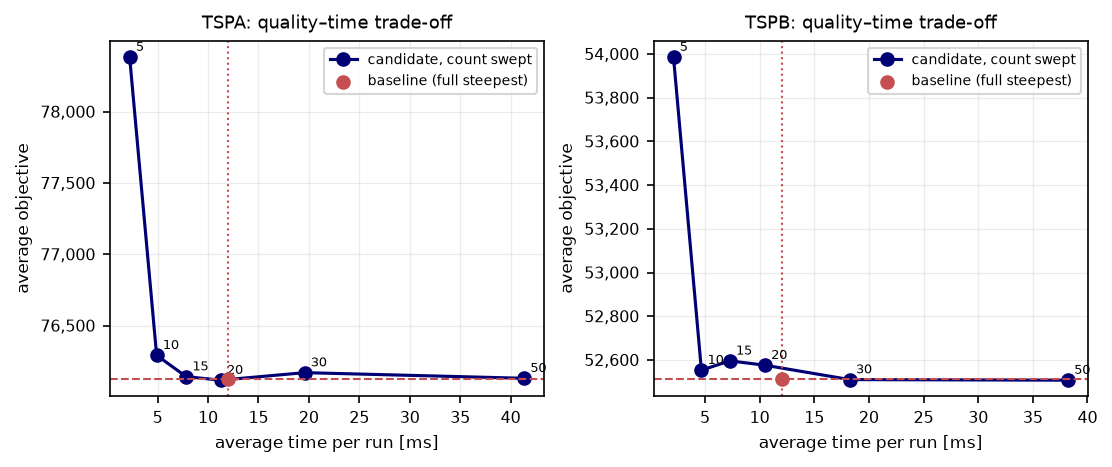

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(7.3, 3.0), layout="constrained")
for ax, name in zip(axes, INSTANCES):
    base_ms = summary[(summary.instance == name) &
                      (summary.method == BASELINE)]["time_ms"].iloc[0] / RUNS
    base_obj = summary[(summary.instance == name) &
                       (summary.method == BASELINE)]["average"].iloc[0]
    ax.plot(sweep[f"{name} ms"], sweep[f"{name} avg"], "o-",
            color=COLORS[CAND[0]], label="candidate, count swept")
    for v, x, y in zip(sweep.index, sweep[f"{name} ms"], sweep[f"{name} avg"]):
        ax.annotate(str(v), (x, y), textcoords="offset points", xytext=(3, 3),
                    fontsize=6)
    ax.axhline(base_obj, color="#c44e52", ls="--", lw=1.0)
    ax.axvline(base_ms, color="#c44e52", ls=":", lw=1.0)
    ax.scatter([base_ms], [base_obj], color="#c44e52", zorder=5,
               label="baseline (full steepest)")
    ax.set_title(f"{name}: quality–time trade-off")
    ax.set_xlabel("average time per run [ms]")
    ax.set_ylabel("average objective")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
    ax.grid(alpha=0.25, lw=0.6)
    ax.set_axisbelow(True)
    ax.legend(fontsize=6.5)
fig.savefig(FIG / "tradeoff.png", bbox_inches="tight")
plt.show()

### 5.5 Distribution of results

The box plots compare the candidate method with the baseline over the 200 runs.

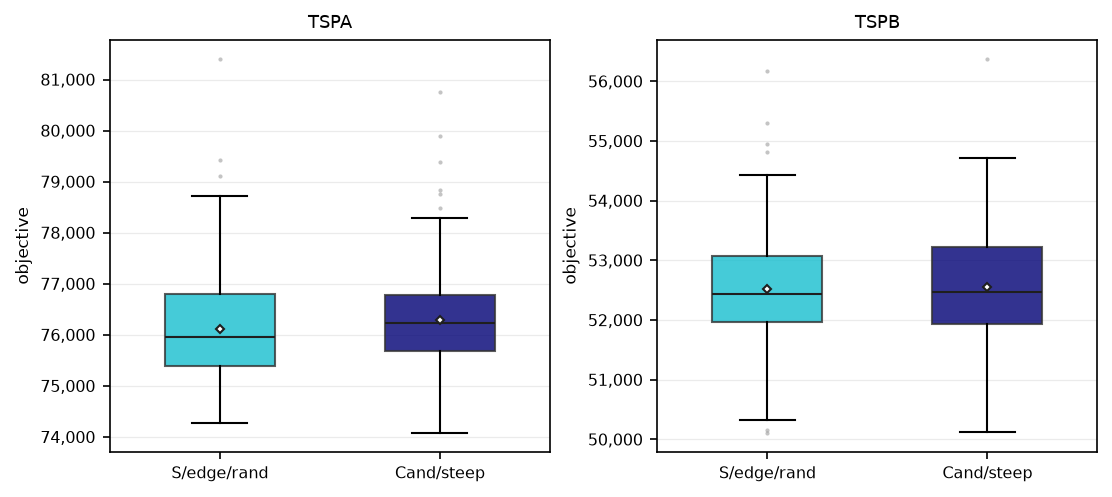

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(7.3, 3.2), layout="constrained")
group = [BASELINE, CAND[0]]
for ax, name in zip(axes, INSTANCES):
    data = [runs.loc[(runs.instance == name) & (runs.method == m),
                     "objective"].to_numpy() for m in group]
    bp = ax.boxplot(
        data, tick_labels=[SHORT[m] for m in group], widths=0.5,
        patch_artist=True, showmeans=True,
        medianprops=dict(color="#1f1f1f", lw=1.0),
        meanprops=dict(marker="D", markerfacecolor="white",
                       markeredgecolor="#1f1f1f", markersize=3.0),
        flierprops=dict(marker="o", markersize=2.0, markerfacecolor="#8a8a8a",
                        markeredgecolor="none", alpha=0.5),
    )
    for patch, m in zip(bp["boxes"], group):
        patch.set_facecolor(COLORS[m])
        patch.set_alpha(0.8)
        patch.set_edgecolor("#333333")
    ax.set_title(name)
    ax.set_ylabel("objective")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
    ax.grid(axis="y", alpha=0.25, lw=0.6)
    ax.set_axisbelow(True)
fig.savefig(FIG / "distributions.png", bbox_inches="tight")
plt.show()

## 6. Best solutions

Each panel shows the best cycle found by one local-search variant. Grey dots are
nodes that were **not** selected. Selected nodes are drawn with a colour **and**
a radius that both encode the node cost (dark purple, small = cheap; yellow,
large = expensive). Thin arrows show the direction of travel along the cycle.

In [11]:
CMAP = plt.get_cmap("viridis")

def load_tour(name, method):
    row = tours[(tours.instance == name) & (tours.method == method)].iloc[0]
    return np.array([int(v) for v in str(row["tour"]).split()]), row

def draw(ax, name, method, norm, short=True):
    df = COORDS[name]
    tour, row = load_tour(name, method)
    sel = np.zeros(len(df), dtype=bool)
    sel[tour] = True
    x = df.x.to_numpy()
    y = df.y.to_numpy()
    cost = df.cost.to_numpy()

    ax.scatter(x[~sel], y[~sel], s=5, c="#d4d4d4", linewidths=0, zorder=1)
    for i in range(len(tour)):
        a, b = tour[i], tour[(i + 1) % len(tour)]
        ax.annotate("", xy=(x[b], y[b]), xytext=(x[a], y[a]),
                    arrowprops=dict(arrowstyle="-|>", color="#555555", lw=0.42,
                                    shrinkA=2.0, shrinkB=3.0, mutation_scale=5,
                                    alpha=0.75),
                    zorder=2)
    t = (cost[tour] - norm.vmin) / max(1e-9, norm.vmax - norm.vmin)
    ax.scatter(x[tour], y[tour], s=7 + 42 * t, c=cost[tour], cmap=CMAP,
               norm=norm, edgecolors="#1b1b1b", linewidths=0.35, zorder=3)

    label = SHORT[method] if short else LABELS[method]
    ax.set_title(f"{label}\nobjective {nf(row['objective'])}",
                 fontsize=7.0 if short else 8.2, pad=3)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_color("#dcdcdc")

def best_figure(name):
    norm = mpl.colors.Normalize(*COST_RANGE[name])
    group = LS + CAND
    ncol = 3
    nrow = (len(group) + ncol - 1) // ncol
    fig, axes = plt.subplots(nrow, ncol, figsize=(7.3, 2.25 * nrow),
                             layout="constrained")
    axes = np.atleast_1d(axes).ravel()
    for ax, method in zip(axes, group):
        draw(ax, name, method, norm, short=True)
    for ax in axes[len(group):]:
        ax.axis("off")
    fig.suptitle(f"{name}: best solution for each local-search variant", fontsize=11)
    sm = mpl.cm.ScalarMappable(norm=norm, cmap=CMAP)
    sm.set_array([])
    cb = fig.colorbar(sm, ax=list(axes), fraction=0.022, pad=0.015)
    cb.set_label("node cost", fontsize=7.5)
    cb.ax.tick_params(labelsize=6.5)
    fig.savefig(FIG / f"best_{name}.png", bbox_inches="tight")
    plt.show()

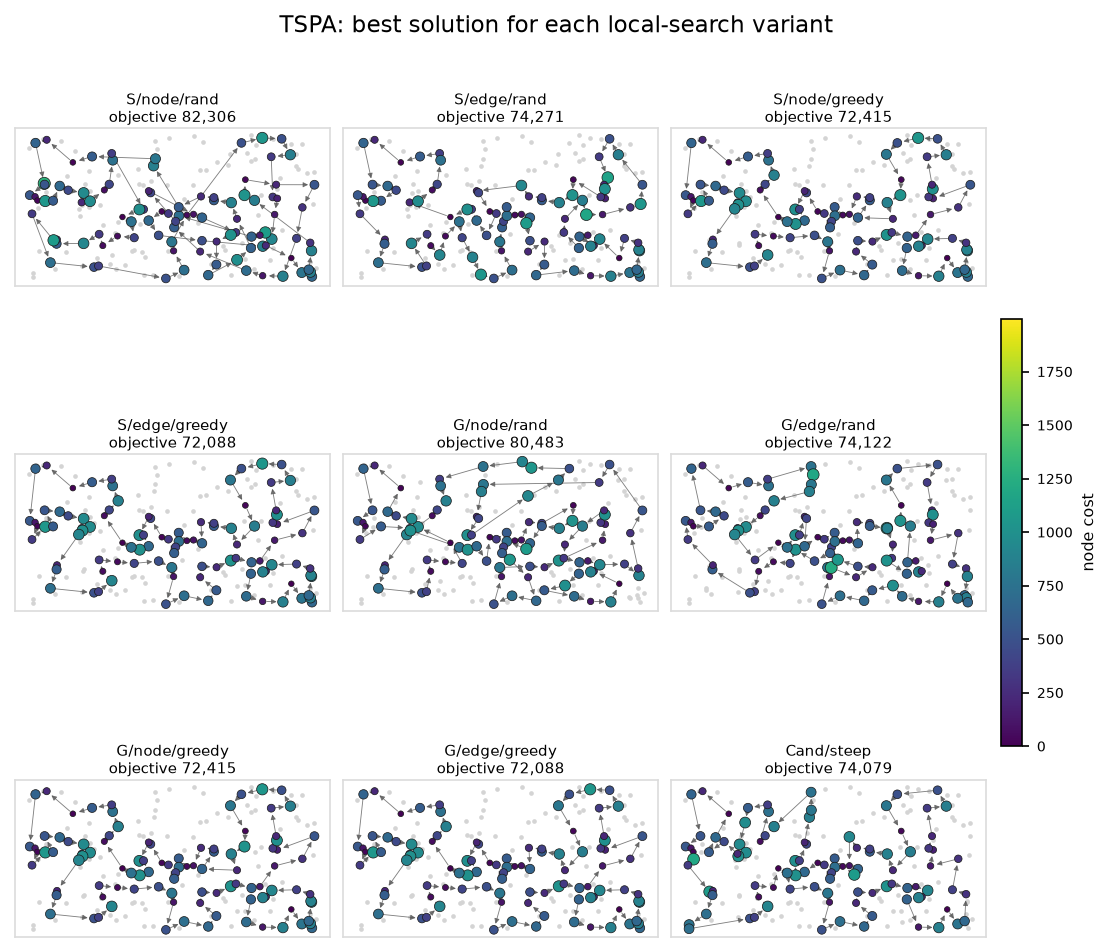

In [12]:
best_figure("TSPA")

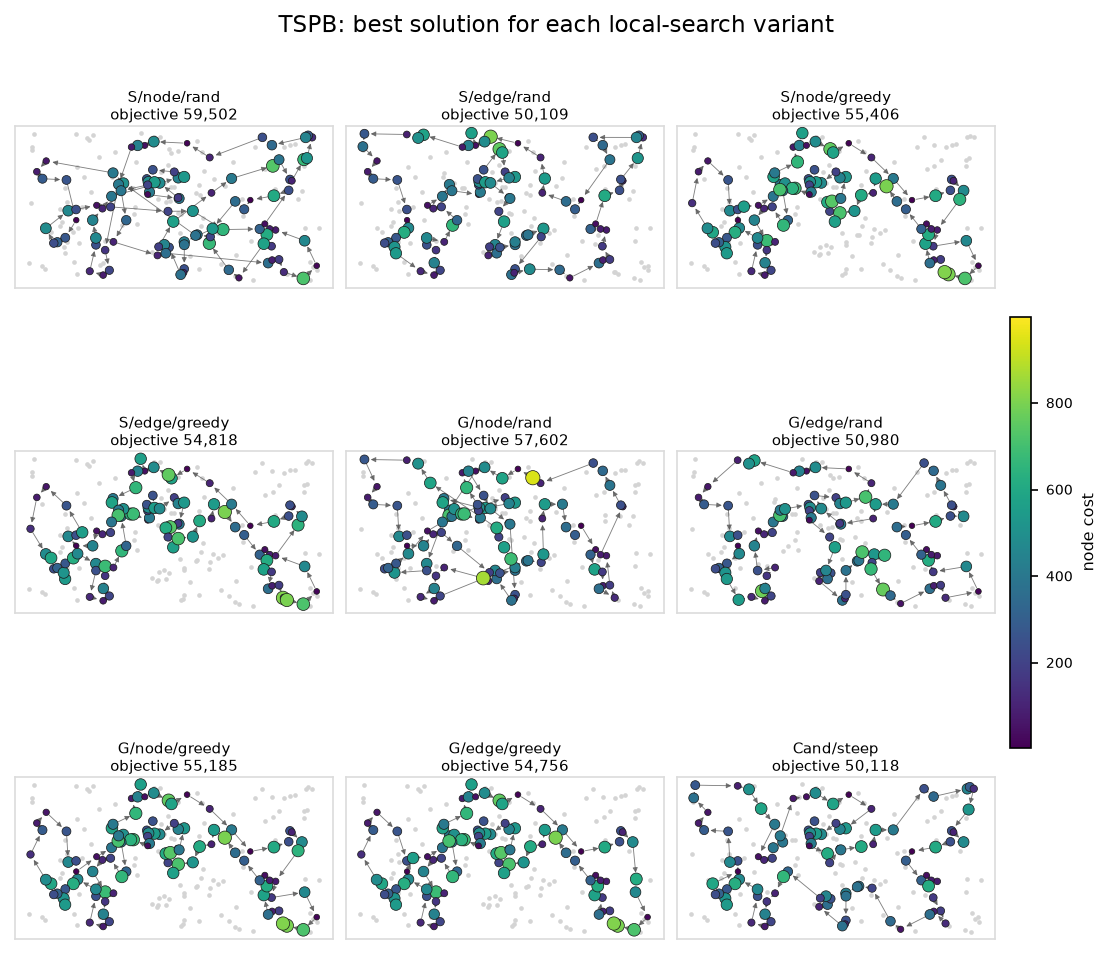

In [13]:
best_figure("TSPB")

## 7. Best solutions as node lists

All indices are **0-based**; the list is the cycle order and the closing arc runs
from the last node back to the first one. Every tour visits exactly `k` distinct
nodes. The complete input for this section is in `best_tours.csv`.

In [14]:
for name in INSTANCES:
    print(name)
    for method in LS + CAND:
        _, row = load_tour(name, method)
        idx = str(row["tour"]).split()
        print(f"\n{LABELS[method]} — objective {nf(row['objective'])} "
              f"(distance {nf(row['distance'])}, costs {nf(row['costs'])}), "
              f"first node {int(row['first_node'])}:")
        for i in range(0, len(idx), 16):
            print("  " + " ".join(idx[i:i + 16]))
    print()

TSPA

Steepest, node swap, random start — objective 82,306 (distance 30,793, costs 51,513), first node 35:
  35 156 180 28 87 141 187 30 161 127 97 95 168 69 171 2
  114 181 135 73 177 136 163 29 101 178 3 50 93 113 43 106
  150 179 144 67 185 45 84 42 89 107 88 78 193 153 170 159
  85 142 164 1 147 47 130 64 57 182 58 140 53 16 51 36
  131 176 72 134 158 192 138 151 174 8 54 9 33 52 139 112
  91 80 48 31 82 60 116 149 63 11 49 108 152 100 123 90
  132 76 71 157

Steepest, edge swap, random start — objective 74,271 (distance 22,246, costs 52,025), first node 157:
  157 91 80 48 31 60 108 152 49 11 63 149 116 168 97 127
  69 171 2 161 30 187 189 141 28 87 98 25 114 181 135 73
  140 53 179 52 177 36 131 99 84 58 134 158 192 182 57 64
  88 78 193 153 170 146 159 130 107 113 106 150 89 42 151 176
  174 85 81 93 47 37 147 101 29 178 59 1 169 50 3 164
  142 8 54 9 33 143 51 16 67 144 45 185 35 156 180 123
  90 132 76 71

Steepest, node swap, greedy start — objective 72,415 (distance 21,395, 

## 8. Conclusions

**Speed.** Restricting the steepest local search to candidate moves evaluates
about six times fewer deltas and is about 2.5 times faster. The scan still
visits `O(k · count + (n−k) · count)` descriptors per iteration instead of the
full `O(k·(n−k) + k²)` neighbourhood, but the broadened inter-route relation and the
per-run candidate-list construction keep the speed-up below the raw delta ratio.

**Quality.** The quality loss is very small — well below one percent on both
instances. This is much better than a one-sided scan because the candidate
relation for node exchanges is effectively undirected: a candidate edge stored
only in the unselected endpoint's list is still used. The default `count = 10`
is a good compromise; larger lists recover almost the full baseline quality, at
the cost of reaching or exceeding the baseline running time. Candidate lists are
rebuilt for every run, so the sweep is not biased by amortising their
construction over the 200 runs.

**Loop organisation.** The loops walk candidate edges directly, so no
non-candidate move is ever constructed or filtered. The inter-route exchange
removes a tour neighbour of the anchor rather than the anchor itself, which
guarantees that the candidate edge is actually introduced. A second scan from
the unselected endpoint handles candidate edges stored only in that endpoint's
list; occasionally a 2-opt move is reachable from two candidate edges and is
evaluated twice, which is harmless.